# 01: Exploring the ABO product catalogue


Data: [Amazon Berkeley Objects](https://amazon-berkeley-objects.s3.amazonaws.com/index.html) (CC BY 4.0),
loaded into Postgres with `listingaudit.data.load_abo`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from sqlalchemy import create_engine

from listingaudit.config import settings
from listingaudit.data.categories import RULE_GROUPS, rule_group

engine = create_engine(settings.sqlalchemy_url)
pd.set_option("display.max_colwidth", 80)


def sql(query: str) -> pd.DataFrame:
    return pd.read_sql(query, engine)

## 1. How big is it?

In [2]:
sql("""
    SELECT count(*)                      AS listings,
           count(DISTINCT item_id)       AS products,
           count(DISTINCT domain_name)   AS amazon_sites,
           count(DISTINCT product_type)  AS product_types,
           (SELECT count(*) FROM images) AS photos
    FROM listings
""")

,listings,products,amazon_sites,product_types,photos
0,147702,145615,32,576,398212


There are more listings than products: the same product (`item_id`) can be listed on
several Amazon sites, each with its own title and language. That's why a listing is
identified by `item_id` **and** `domain_name` in the database.

In [3]:
sql("""
    SELECT item_id, domain_name, text_language, item_name
    FROM listings
    WHERE item_id = (
        SELECT item_id FROM listings GROUP BY item_id HAVING count(*) = 3 ORDER BY item_id LIMIT 1
    )
""")

,item_id,domain_name,text_language,item_name
0,B001V9LBAC,amazon.it,it_IT,Pinzon 160-gram Yarn-Dye Flanella Copripiumino
1,B001V9LBAC,amazon.com.mx,es_MX,"Pinzon Edredón 160 Gramos, Franela de Hilado teñido"
2,B001V9LBAC,amazon.co.uk,en_US,Pinzon 160-Gram Yarn-Dye Flannel Duvet Cover


## 2. Where do the listings come from?

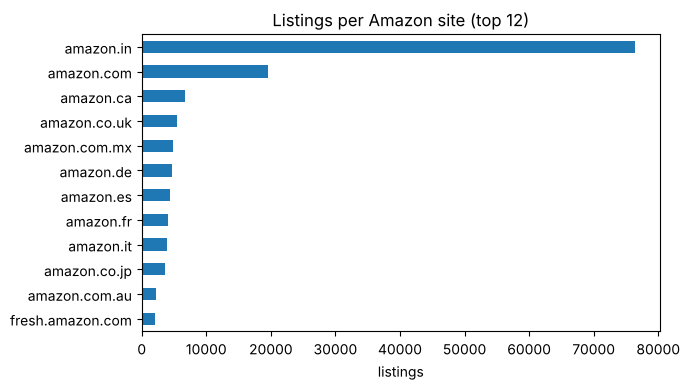

In [4]:
sites = sql(
    "SELECT domain_name, count(*) AS listings FROM listings GROUP BY 1 ORDER BY 2 DESC LIMIT 12"
)
ax = sites.plot.barh(x="domain_name", y="listings", legend=False, figsize=(7, 4))
ax.invert_yaxis()
ax.set_xlabel("listings")
ax.set_ylabel("")
ax.set_title("Listings per Amazon site (top 12)")
plt.tight_layout()

Over half the listings are from amazon.in (India). Germany (amazon.de) has a few thousand.

## 3. What kinds of products?

In [5]:
types = sql("SELECT product_type, count(*) AS listings FROM listings GROUP BY 1 ORDER BY 2 DESC")
types["share"] = (types.listings / types.listings.sum() * 100).round(1)
types.head(15)

,product_type,listings,share
0,CELLULAR_PHONE_CASE,64853,43.9
1,SHOES,12965,8.8
2,GROCERY,6546,4.4
3,HOME,5264,3.6
4,HOME_BED_AND_BATH,3082,2.1
5,HOME_FURNITURE_AND_DECOR,2255,1.5
6,CHAIR,2100,1.4
7,BOOT,2009,1.4
8,SANDAL,1845,1.2
9,FINERING,1540,1.0


Phone cases are about 44% of everything, and none of the product-specific rules apply to
them. The product types that matter for each rule are grouped in
`listingaudit/data/categories.py`:

In [6]:
focus = types[types.product_type.map(rule_group).notna()].copy()
focus["rule_group"] = focus.product_type.map(rule_group)
focus.groupby("rule_group").listings.sum().sort_values(ascending=False)

rule_group
general         19455
unit_price       7711
textile          4667
energy_label     2069
warnings           42
Name: listings, dtype: int64

## 4. Which languages?

Every text field in ABO is a list of translations. Each listing is read in one language
(English first, then German), so a row never mixes languages. The result:

In [7]:
sql("""
    SELECT text_language, count(*) AS listings
    FROM listings GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""")

,text_language,listings
0,en_IN,76437
1,en_US,26390
2,en_GB,8146
3,en_CA,6726
4,es_MX,4827
5,es_ES,4523
6,fr_FR,4154
7,it_IT,3938
8,de_DE,2254
9,en_AU,2142


## 5. What's missing?

The rules need specific facts: fabric content for textiles, weight or pack size for groceries,
a photo for everything. How often are they actually there? (% of listings with a value)

In [8]:
columns = [
    "brand",
    "color",
    "material",
    "fabric_type",
    "bullet_points",
    "description",
    "weight_grams",
    "main_image_id",
]
filled = ", ".join(
    f"round(100.0 * count(*) FILTER (WHERE {c} IS NOT NULL"
    + (f" AND cardinality({c}) > 0" if c == "bullet_points" else "")
    + f") / count(*), 1) AS {c}"
    for c in columns
)
groups = " ".join(
    f"WHEN product_type IN ({', '.join(repr(t) for t in ts)}) THEN '{g}'"
    for g, ts in RULE_GROUPS.items()
)
sql(f"""
    SELECT CASE {groups} ELSE 'other' END AS rule_group, count(*) AS listings, {filled}
    FROM listings GROUP BY 1 ORDER BY 2 DESC
""").set_index("rule_group")

,listings,brand,color,material,fabric_type,bullet_points,description,weight_grams,main_image_id
rule_group,,,,,,,,,
other,113758,100.0,82.3,36.3,3.6,90.5,2.9,79.4,99.6
general,19455,100.0,80.0,38.8,16.5,80.3,1.2,37.3,99.7
unit_price,7711,100.0,1.0,0.7,0.0,93.3,0.5,59.9,99.5
textile,4667,99.7,67.2,56.2,15.4,66.0,0.7,55.8,99.9
energy_label,2069,100.0,91.3,38.5,0.0,78.4,0.5,67.2,100.0
warnings,42,100.0,69.0,59.5,0.0,90.5,2.4,50.0,100.0


Things that stand out:

- **`fabric_type` is missing for about 85% of textiles.** 
- **Descriptions are rare** (under 3%). Most of the product text lives in the title and bullet points.
- **Weight is missing for about 40% of the unit-price products** (groceries, cosmetics, cleaning
  products), which matters for the price-per-kilo rule.

## 6. Weights and pack sizes

In [9]:
sql("""
    SELECT raw -> 'item_weight' -> 0 ->> 'unit' AS unit, count(*) AS listings
    FROM listings WHERE raw ? 'item_weight' GROUP BY 1 ORDER BY 2 DESC
""")

,unit,listings
0,grams,69720
1,pounds,27924
2,kilograms,4369
3,ounces,4179
4,milligrams,2


Weights come in five different units (grams, pounds, kilograms, ounces, milligrams), so the
loader converts everything to grams (`weight_grams`). ABO's own `normalized_value` field
doesn't normalise anything: it repeats the original unit.

For groceries, the pack size needed for the price per kilo usually isn't in a field at all.
It's hidden in the title, often in US units:

In [10]:
grocery = sql("""
    SELECT item_name, weight_grams FROM listings
    WHERE product_type = 'GROCERY' AND text_language LIKE 'en%%'
    ORDER BY md5(item_id) LIMIT 8
""")
grocery

,item_name,weight_grams
0,"365 Everyday Value, Pork & Maple Breakfast Sausage, 10 ct (Frozen)",199.581
1,"Amazon Meal Kits, Kung Pao Chicken with Cashews & Gai Lan, Serves 2",1079.550
2,"Whole Foods Market, Fresh Mozzarella Medallions, 8 oz",NaN
3,"Whole Foods Market, Original Crostini, 6 oz",170.097
4,"365 Everyday Value, Organic Pepper Jack Cheese, Slices, 12 oz",NaN
5,"365 EVERYDAY VALUE Creme Brulee Almond & Hazelnut Nut Mix, 12 OZ",362.874
6,SHELL - RTC TrayBake2 - Seafood 2,NaN
7,"365 Everyday Value, Gluten Free Chocolate Chip Cookie Mix, 15 oz",426.377


In [11]:
pattern = r"\b\d+(?:\.\d+)?\s*(?:oz|fl oz|lb|lbs|g|kg|ml|l|pt|qt|gal|ct|count)\b"
titles = sql("SELECT item_name FROM listings WHERE product_type = 'GROCERY'").item_name
has_size = titles.str.contains(pattern, case=False, regex=True)
print(f"{has_size.mean():.0%} of grocery titles contain a pack size like '10 OZ' or '500 g'")

72% of grocery titles contain a pack size like '10 OZ' or '500 g'


So the price-per-kilo check needs to **read the pack size out of the title** and convert US
units (oz, pt, lb) to metric. The rest (titles like "Serves 2") have no usable pack size
at all.

## 7. A surprise: shared photos

While downloading photos I noticed the same photo being downloaded twice, and product counts
that didn't add up. The reason: many products share the same main photo.

In [12]:
sql("""
    SELECT count(*) FILTER (WHERE used_by_items = 1) AS photos_used_by_one_product,
           count(*) FILTER (WHERE used_by_items > 1) AS photos_shared,
           max(used_by_items)                         AS most_products_on_one_photo
    FROM images WHERE used_by_items IS NOT NULL
""")

,photos_used_by_one_product,photos_shared,most_products_on_one_photo
0,112458,11053,740


In [13]:
shared = sql("""
    SELECT i.image_id, i.path, i.used_by_items, i.used_by_types,
           (SELECT min(brand) FROM listings l WHERE l.main_image_id = i.image_id) AS a_brand
    FROM images i WHERE used_by_items > 20 ORDER BY used_by_items DESC LIMIT 5
""")
shared[["image_id", "used_by_items", "used_by_types", "a_brand"]]

,image_id,used_by_items,used_by_types,a_brand
0,61OnkGVhMWL,740,76,Amazon Basics
1,71qXvJLzyTL,298,1,UMI
2,31lJBp1dALL,156,5,Fresh
3,61w4fs2ESyL,149,27,Amazon Basics
4,61kVdTXTJ4L,87,11,AmazonBasics


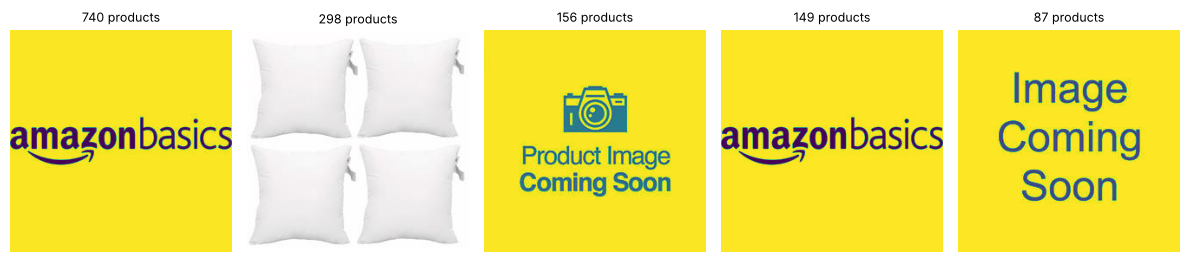

In [14]:
import io

import httpx

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for ax, row in zip(axes, shared.itertuples(), strict=False):
    url = f"{settings.abo_base_url}/images/small/{row.path}"
    ax.imshow(Image.open(io.BytesIO(httpx.get(url).content)))
    ax.set_title(f"{row.used_by_items} products", fontsize=9)
    ax.axis("off")
plt.tight_layout()

The most-shared "photos" are brand logos and "image coming soon" placeholders, used by
hundreds of unrelated products. A photo checker comparing these with the product text would
raise false alarms everywhere.

**Fix:** the loader counts how many products use each photo (`used_by_items`,
`used_by_types`), and the photo download only picks products whose photo belongs to them alone.

## 8. The photo sample

In [15]:
sample = sql("""
    SELECT DISTINCT ON (l.item_id) l.product_type, l.item_name, l.color, i.local_file
    FROM listings l JOIN images i ON i.image_id = l.main_image_id
    WHERE i.local_file IS NOT NULL
    ORDER BY l.item_id
""")
sample["rule_group"] = sample.product_type.map(rule_group)
sample.rule_group.value_counts()

rule_group
unit_price      596
general         500
energy_label    410
textile         338
warnings         31
Name: count, dtype: int64

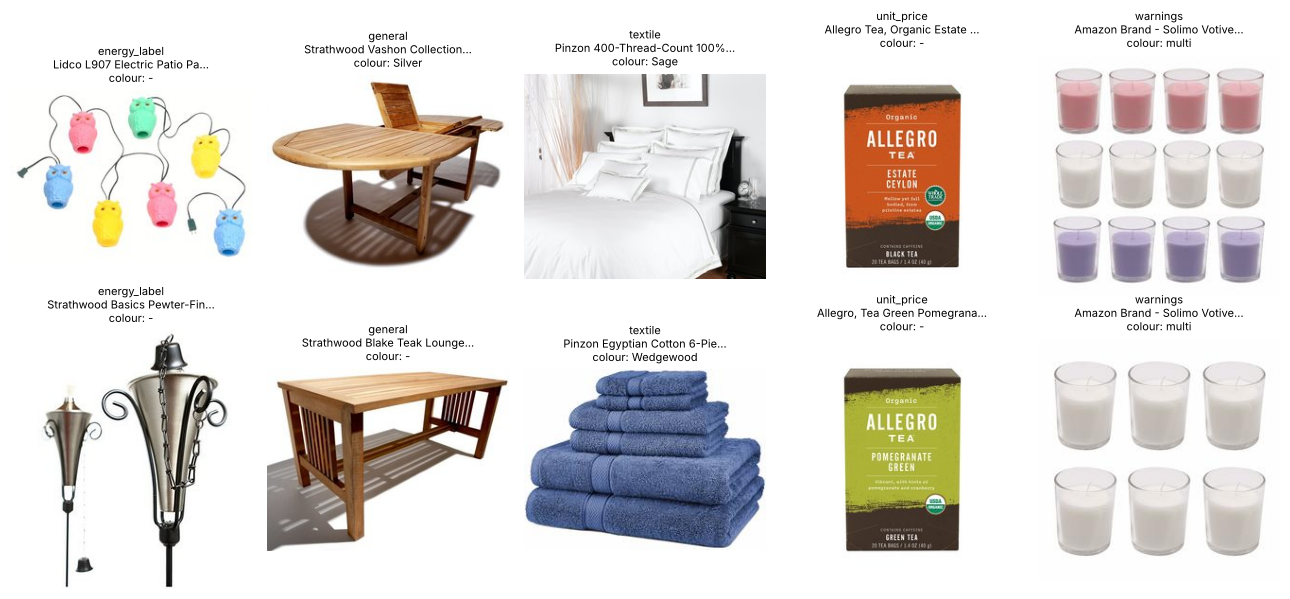

In [16]:
picks = sample.groupby("rule_group").head(2)
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, row in zip(axes.T.flat, picks.sort_values("rule_group").itertuples(), strict=False):
    ax.imshow(Image.open(settings.data_dir / row.local_file))
    colour = row.color if isinstance(row.color, str) else "-"
    ax.set_title(f"{row.rule_group}\n{row.item_name[:28]}...\ncolour: {colour}", fontsize=8)
    ax.axis("off")
plt.tight_layout()